# Lecture 4 — Scatter & Bubble Charts: Gapminder

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt

df = px.data.gapminder()
print(f'Loaded: {len(df):,} rows')
print(df.head())
print('Years:', sorted(df['year'].unique()))
print('Continents:', sorted(df['continent'].unique()))


Loaded: 1,704 rows\n       country continent  year  lifeExp       pop   gdpPercap iso_alpha  iso_num
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG        4
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG        4
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG        4
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG        4
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG        4\nYears: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]\nContinents: ['Africa', 'Americas', 'Asia', 'Europe', 'Oceania']\n

## Task 1 — Scatter: change across the Americas, 2002 to 2007

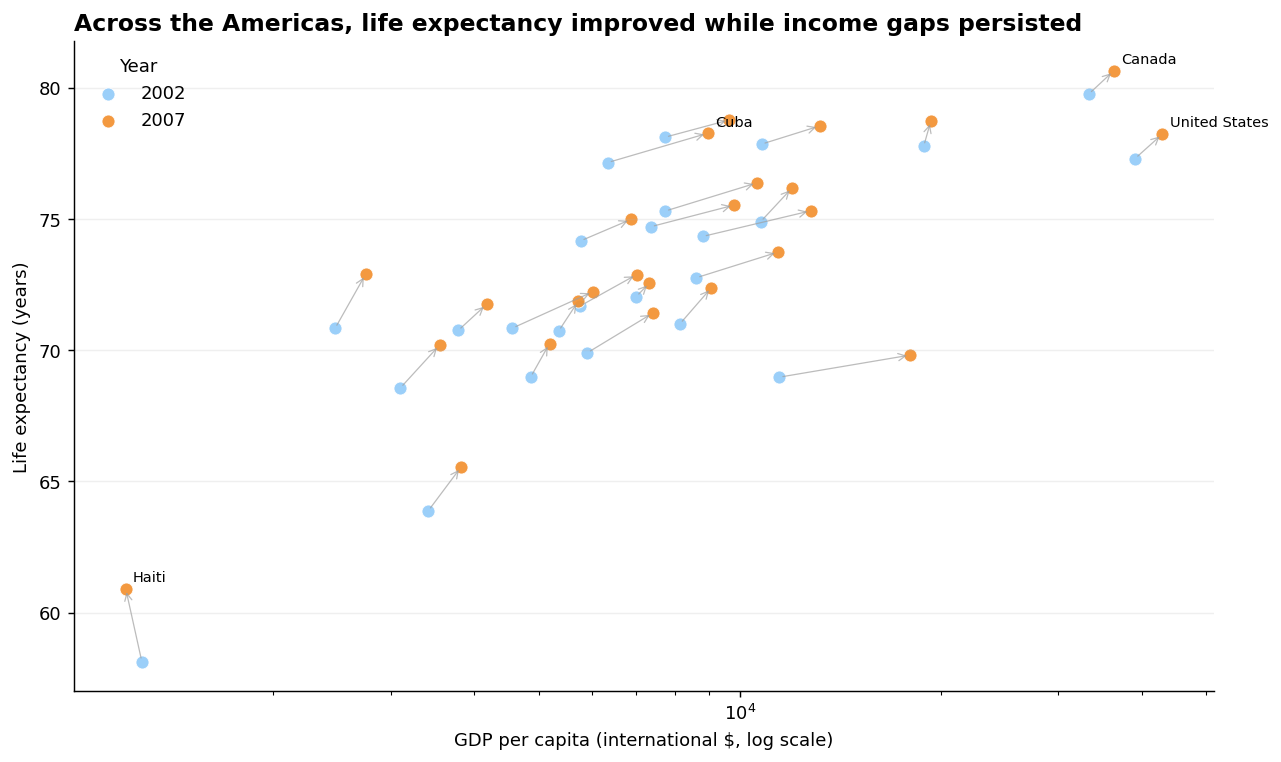

In [2]:
# Compare the Americas in 2002 and 2007.
years = [2002, 2007]
continent_choice = 'Americas'
plot_df = df.loc[(df['continent'] == continent_choice) & (df['year'].isin(years))]
y2002 = plot_df.loc[plot_df['year'] == 2002].set_index('country')
y2007 = plot_df.loc[plot_df['year'] == 2007].set_index('country')
countries = y2002.index.intersection(y2007.index)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(y2002.loc[countries, 'gdpPercap'], y2002.loc[countries, 'lifeExp'],
           s=52, color='#90CAF9', edgecolor='white', linewidth=.5, label='2002', alpha=.9)
ax.scatter(y2007.loc[countries, 'gdpPercap'], y2007.loc[countries, 'lifeExp'],
           s=52, color='#F28E2B', edgecolor='white', linewidth=.5, label='2007', alpha=.9)
for country in countries:
    ax.annotate('', xy=(y2007.loc[country, 'gdpPercap'], y2007.loc[country, 'lifeExp']),
                xytext=(y2002.loc[country, 'gdpPercap'], y2002.loc[country, 'lifeExp']),
                arrowprops=dict(arrowstyle='->', color='#A0A0A0', linewidth=.7, alpha=.7))
for country in ['United States', 'Canada', 'Haiti', 'Cuba']:
    if country in countries:
        ax.annotate(country, (y2007.loc[country, 'gdpPercap'], y2007.loc[country, 'lifeExp']),
                    xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.set_xscale('log')
ax.set_title('Across the Americas, life expectancy improved while income gaps persisted',
             loc='left', fontsize=13, fontweight='bold')
ax.set_xlabel('GDP per capita (international $, log scale)')
ax.set_ylabel('Life expectancy (years)')
ax.grid(axis='y', alpha=.2)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, title='Year')
plt.tight_layout()
plt.show()


## Task 2 — Bubble chart: Europe in the global picture

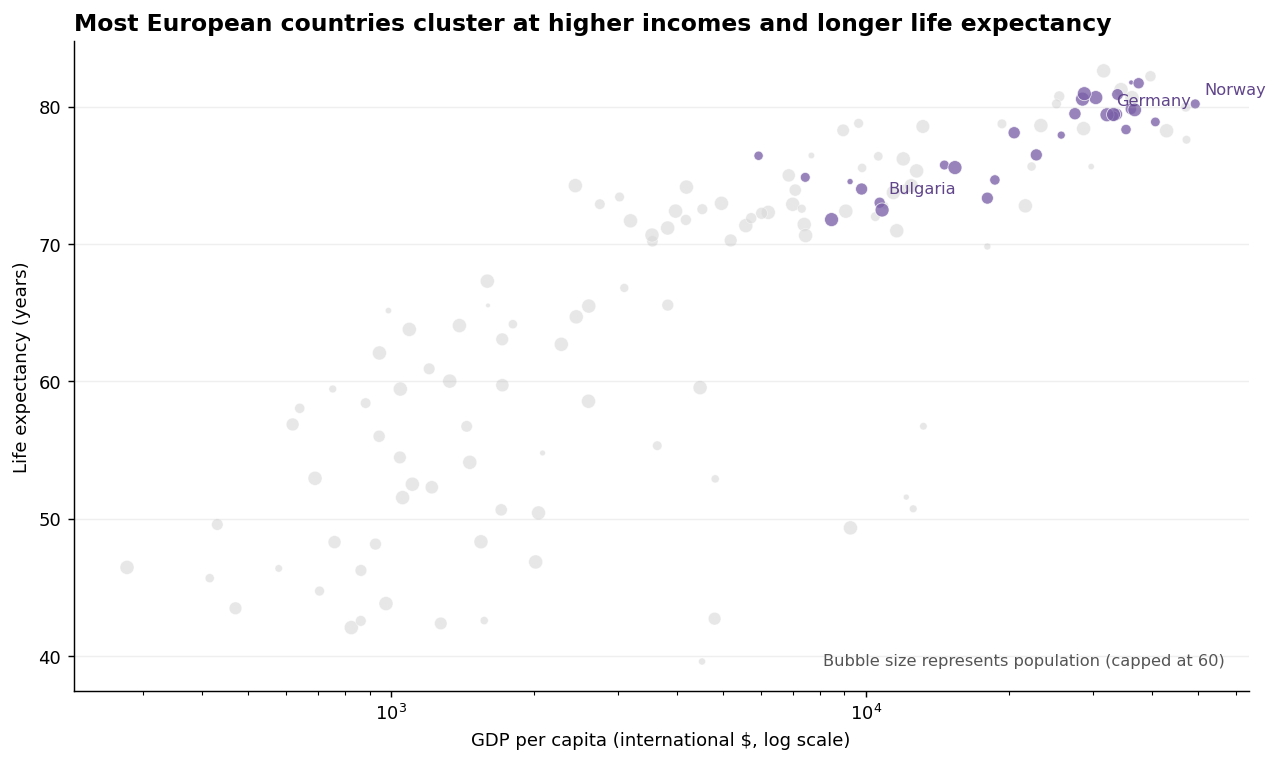

In [3]:
# Full 2007 dataset: highlight Europe, with all other continents in grey.
year_choice = 2007
highlight_continent = 'Europe'
bubble_df = df.loc[df['year'] == year_choice].copy()
others = bubble_df.loc[bubble_df['continent'] != highlight_continent]
highlight = bubble_df.loc[bubble_df['continent'] == highlight_continent]

# Marker size is based on population, capped at size_max = 60.
def bubble_size(population, size_max=60):
    return np.minimum(np.sqrt(population / 1_000_000) * 14, size_max)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(others['gdpPercap'], others['lifeExp'], s=bubble_size(others['pop']),
           color='#D9D9D9', alpha=.62, edgecolors='white', linewidth=.35)
ax.scatter(highlight['gdpPercap'], highlight['lifeExp'], s=bubble_size(highlight['pop']),
           color='#7B61A8', alpha=.78, edgecolors='white', linewidth=.45)
for country in ['Bulgaria', 'Germany', 'Norway']:
    row = highlight.loc[highlight['country'] == country]
    if not row.empty:
        r = row.iloc[0]
        ax.annotate(country, (r['gdpPercap'], r['lifeExp']), xytext=(5, 5),
                    textcoords='offset points', fontsize=9, color='#60458B')
ax.set_xscale('log')
ax.set_title('Most European countries cluster at higher incomes and longer life expectancy',
             loc='left', fontsize=13, fontweight='bold')
ax.set_xlabel('GDP per capita (international $, log scale)')
ax.set_ylabel('Life expectancy (years)')
ax.grid(axis='y', alpha=.2)
ax.spines[['top', 'right']].set_visible(False)
ax.text(.98, .04, 'Bubble size represents population (capped at 60)',
        transform=ax.transAxes, ha='right', fontsize=9, color='#555555')
plt.tight_layout()
plt.show()
